# 44 · 토큰화와 언어 데이터: 문자열을 예측할 배열로

과일 이름이 적힌 문장 `red apple is sweet.`을 숫자 배열로 바꾸고, 다음 조각의 확률을 학습합니다. 이 노트북은 **어디서 문자열을 자르고 무엇을 정답으로 삼는지**를 직접 구현합니다. 완성된 tokenizer나 사전학습 모델을 불러오지 않습니다.

- 준비물: [02 확률·CE](../00_기초/02_probability_and_losses.ipynb), [09 Transformer](../01_아키텍처/09_transformer.ipynb)의 토큰·mask, [15 분할](../02_연결/15_experiments_evaluation.ipynb), [20 시퀀스 모델](../03_구조조합/20_sequence_encoder_decoder.ipynb)의 BOS/EOS입니다.
- 순서: ① 문자와 byte → ② BPE 학습 → ③ 문서 경계와 shift → ④ embedding·CE·전체 backward → ⑤ 독립 문장의 평가와 생성입니다.
- 도착점: byte-BPE를 train 문서만으로 학습하고, 이전 토큰 하나를 보는 작은 언어모델을 학습합니다. 45 decoder GPT에서는 이전 문맥 전체를 attention으로 읽습니다.

> **용어**
>
> - **토큰(token)**: 모델이 한 번에 읽거나 예측하는 조각입니다. 문자 하나, byte 하나, 합쳐진 여러 byte가 될 수 있습니다.
> - **어휘(vocabulary)**: token ID와 조각을 연결한 표입니다. ID는 크기 비교용 숫자가 아니라 행 번호입니다.
> - **토큰화(tokenization)**: 문자열을 token ID 열로 바꾸는 규칙입니다. 역방향인 detokenization은 조각을 다시 잇습니다.
> - **자기회귀(autoregressive)**: 앞부분을 조건으로 다음 토큰의 확률을 차례로 곱하는 방식입니다.

### 읽는 법

| 표시 | 읽을 것 |
|---|---|
| 🔑 핵심 | 수식·shape·함수를 다시 설명합니다 |
| 🔍 확인 | 출력과 경계 검산을 읽습니다 |
| 📎 참고 | 코드 관용구·범위·출처를 확인합니다 |
| ✏️ 연습 | 핵심 한두 줄을 채웁니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. tokenizer의 학습 자료와 언어모델 평가 자료를 분리합니다. 모르는 문자를 byte로 표현하는 것과 그 뜻을 아는 것은 다릅니다.
2. 문서마다 BOS→본문→EOS를 이동하고 유효 target만 평균합니다. 문서 경계와 padding은 서로 다른 문제입니다.
3. PPL은 토큰 분모에 의존합니다. 토큰화가 다른 두 PPL을 그대로 비교하지 않습니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/tokenization_plots.py)

In [1]:
# 준비 셀: 독립 실행을 위한 경로·배열·그림 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.utils import setup_plots, run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.tokenization_plots import (
    plot_token_units, plot_pair_merge, plot_shift, plot_embedding_path, plot_token_budget, plot_learning,
)
setup_plots()
print('다운로드 없는 NumPy 토큰화 예제')

다운로드 없는 NumPy 토큰화 예제


## 🔑 1. 같은 글자도 문자 수와 byte 수가 다릅니다

**이 절에서 가져갈 것:** 사람이 보는 글자, Python의 문자, UTF-8 byte는 같은 단위가 아닙니다.

`사과 A`를 네 문자로 읽어도 컴퓨터에 저장하는 byte는 여덟 개입니다. Python의 `list(text)`는 Unicode code point를 나누고, `text.encode('utf-8')`는 0–255의 byte로 바꿉니다. 한글 음절은 이 예에서 각각 세 byte입니다. 조각 하나만 UTF-8로 읽을 수 없어도 **전체 byte를 먼저 잇고** 해독하면 원문이 복원됩니다.

> **용어** · **Unicode code point**는 문자 부호에 붙인 정수입니다. **UTF-8**은 이를 가변 길이 byte로 저장하는 규칙입니다. **정규화(normalization)**는 서로 다르게 저장된 글자를 정한 형태로 바꾸는 전처리이며, 원래 byte를 보존하는 연산이 아닐 수 있습니다.
>
> **코드** · `list(bytes)`는 각 byte를 정수로 꺼냅니다. `bytes(ids).decode('utf-8')`는 byte 열을 엄격하게 해독합니다. 빈 문자열은 빈 목록이 됩니다.

토큰 ID 열은 길이가 문장마다 다른 `(T,)`입니다. byte 어휘는 256개지만, 글자 어휘는 train에서 보지 않은 문자를 처리하는 별도 규약이 필요합니다. 이번 byte 경로는 입력 문자열을 정규화하거나 공백을 삭제하지 않습니다.

In [2]:
unit_text = '사과 A'
unit_characters = list(unit_text)
unit_bytes = list(unit_text.encode('utf-8'))
print('문자 수', len(unit_characters), '· byte 수', len(unit_bytes))

문자 수 4 · byte 수 8


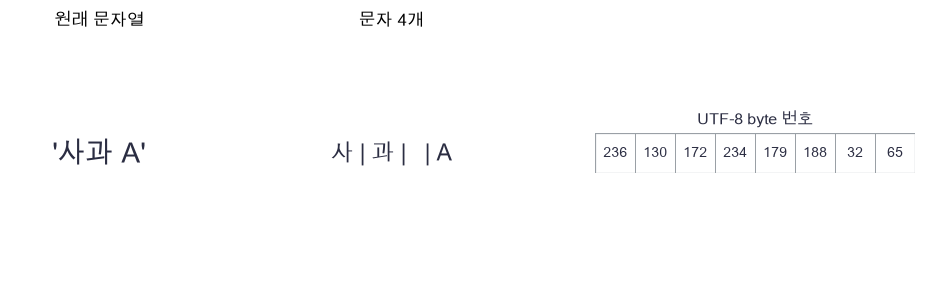

In [3]:
plot_token_units(unit_text, unit_characters, unit_bytes)

🔍 **확인** · 공백도 byte 32로 남습니다. `split()`으로 단어를 나눈 뒤 공백 하나로 합치면 연속 공백·줄바꿈을 잃을 수 있습니다. 문자 단위 역시 화면의 글자 덩어리와 항상 같지는 않습니다. 아래에서 조합된 악센트와 분리된 악센트가 서로 다른 byte임을 확인합니다.

In [4]:
def utf8_ids(text):
    """정규화 없이 문자열을 0–255 byte 번호의 목록으로 바꿉니다."""
    return list(text.encode('utf-8'))

In [5]:
for original in ['', 'apple  pear\n', '사과', 'é', 'é', '🍎']:
    assert bytes(utf8_ids(original)).decode('utf-8') == original, '공백·Unicode·빈 문자열을 정확히 복원해야 합니다'
assert utf8_ids('é') != utf8_ids('é'), '정규화를 하지 않았으므로 서로 다른 부호열이어야 합니다'
assert len('사과 A') == 4, '문자 수는4여야 합니다'
assert len(utf8_ids('사과 A')) == 8, 'UTF-8 byte 수는8이어야 합니다'
print('문자와 byte 단위 및 정확한 왕복 검산 통과')

문자와 byte 단위 및 정확한 왕복 검산 통과


### ✏️ 연습 1 · byte 번호로 되돌리기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

ids를 byte 열로 묶고 UTF-8 문자열 text로 복원하세요.

In [6]:
def exercise_utf8(ids):
    """byte 번호로 되돌리기의 계산을 완성합니다."""
    ### 구현할 내용: ids를 byte 열로 묶고 UTF-8 문자열 text로 복원하세요.
    raise NotImplementedError
    return text

In [7]:
def check_utf8(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([65, 32, 66]) == 'A B', '공백을 포함한 A B여야 합니다'
    assert candidate([]) == '', '빈 byte 열은 빈 문자열이어야 합니다'
    print("연습 1 통과")

run_check(check_utf8, exercise_utf8, hint="byte 번호로 되돌리기의 수식과 축을 확인하세요.")

☐ exercise_utf8: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: byte 번호로 되돌리기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
text = bytes(ids).decode("utf-8")
```

</details>

## 🔑 2. 자주 붙는 byte 쌍을 train 문서에서만 합칩니다

**이 절에서 가져갈 것:** BPE는 현재 인접 쌍의 빈도를 다시 세어 규칙을 배우고, 평가 때 그 순서를 고정하여 적용합니다.

과일 이름에서 자주 나란히 오는 조각은 매번 따로 읽지 않고 하나로 합칠 수 있습니다. 먼저 `a b a b a`를 번호 `[0,1,0,1,0]`으로 놓습니다. 인접 쌍 `(0,1)`과 `(1,0)`은 각각 두 번입니다. 동률이면 번호 쌍의 사전순으로 `(0,1)`을 골라 새 번호2로 바꾸면 `[2,2,0]`입니다.

$$count(a,b)=\sum_{d}\sum_{t=0}^{T_d-2}\mathbf1[(u_{d,t},u_{d,t+1})=(a,b)].$$

문서 d 안의 인접 쌍만 셉니다. 빈도는 겹침을 포함하지만, 한 규칙을 적용할 때는 왼쪽부터 **겹치지 않게** 바꿉니다. `aaaa`의 `aa` 빈도는3이고 실제 병합 결과는 두 조각입니다.

> **용어** · **BPE(Byte Pair Encoding)**는 빈번한 인접 조각 쌍을 합치는 규칙을 반복 학습하는 방법입니다. 여기서는 byte로 시작하고 문장 안 공백도 병합할 수 있는 교육 구현입니다. [Sennrich 외 원문](https://aclanthology.org/P16-1162/)의 단어 경계 전처리와 완전히 같은 tokenizer는 아닙니다.
>
> **코드** · `zip(ids[:-1], ids[1:])`은 이웃 두 항을 나란히 읽습니다. 사전의 `get(pair,0)`은 없던 쌍을0부터 셉니다. `min(candidates)`는 정수 튜플의 사전순으로 동률을 해결합니다. 컴프리헨션 `[f(x) for x in xs]`는 각 원소에 같은 계산을 적용한 목록입니다.

In [8]:
merge_before = [0, 1, 0, 1, 0]
merge_pairs = np.array([merge_before[:-1], merge_before[1:]]).T
merge_counts = np.array([np.sum(np.all(merge_pairs == [0, 1], axis=1)),
                         np.sum(np.all(merge_pairs == [1, 0], axis=1))])
merge_after_hand = [2, 2, 0]

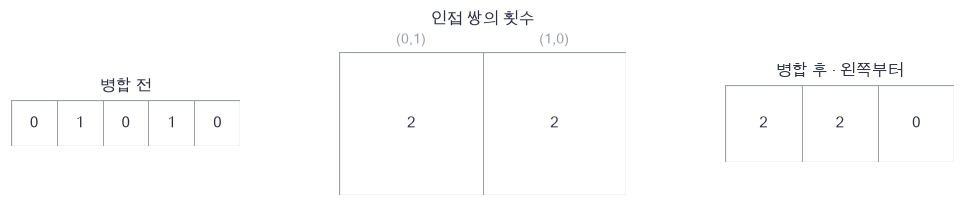

In [9]:
plot_pair_merge(merge_before, merge_counts, ['(0,1)', '(1,0)'], merge_after_hand)

🔍 **확인** · 두 빈도가 같아도 동률 규칙을 정하면 실행할 때마다 같은 결과가 나옵니다. 빈도표는 현재 분할에 대한 값이므로 병합 다음 단계에서 다시 계산합니다. 학습은 이산적인 빈도 선택이며, 뒤의 언어모델 경사하강과 구분합니다.

In [10]:
def pair_counts(documents):
    """문서 경계를 넘지 않고 인접한 쌍을 겹침까지 포함하여 셉니다."""
    counts = {}
    for ids in documents:
        for left, right in zip(ids[:-1], ids[1:]):
            pair = (left, right)
            counts[pair] = counts.get(pair, 0) + 1
    return counts

In [11]:
def merge_pair(ids, pair, new_id):
    """한 쌍을 왼쪽부터 겹치지 않게 바꾸며 나머지 순서는 보존합니다."""
    result = []
    index = 0
    while index < len(ids):
        if index + 1 < len(ids) and (ids[index], ids[index + 1]) == pair:
            result.append(new_id)
            index += 2
        else:
            result.append(ids[index])
            index += 1
    return result

In [12]:
def train_byte_bpe(texts, merges=32):
    """train 문서만으로 빈도 BPE를 배웁니다. 동률은 ID 쌍의 사전순으로 정합니다."""
    # 쓰는 것: utf8_ids (앞 절의 정의·실행 셀)
    # 1) 0–255는 byte, 256–258은 PAD/BOS/EOS 전용으로 예약합니다.
    documents = [utf8_ids(text) for text in texts]
    vocabulary = {i: bytes([i]) for i in range(256)}
    rules = []
    # 2) 매 반복마다 현재 문서의 쌍 빈도를 다시 계산합니다.
    for iteration in range(merges):
        counts = pair_counts(documents)
        if not counts or max(counts.values()) < 2:
            break
        maximum = max(counts.values())
        candidates = [pair for pair in counts if counts[pair] == maximum]
        pair = min(candidates)
        new_id = 259 + iteration
        vocabulary[new_id] = vocabulary[pair[0]] + vocabulary[pair[1]]
        rules.append((pair, new_id))
        documents = [merge_pair(ids, pair, new_id) for ids in documents]
    return vocabulary, rules

In [13]:
def encode_bpe(text, rules):
    """학습된 순서의 병합 규칙을 재사용하며 새 규칙은 만들지 않습니다."""
    # 쓰는 것: utf8_ids (앞 절의 정의·실행 셀)
    ids = utf8_ids(text)
    for pair, new_id in rules:
        ids = merge_pair(ids, pair, new_id)
    return ids

In [14]:
def decode_bpe(ids, vocabulary):
    """본문 token의 byte를 모두 이은 뒤 엄격한 UTF-8로 복원합니다. 특수 ID는 거부합니다."""
    assert all(token in vocabulary for token in ids), '본문 복원에는 PAD/BOS/EOS나 미등록 ID를 넣으면 안 됩니다'
    return b''.join(vocabulary[token] for token in ids).decode('utf-8')

In [15]:
# 쓰는 것: merge_pair, pair_counts (앞 절의 정의·실행 셀)
assert pair_counts([[0,1,0,1,0]]) == {(0,1):2, (1,0):2}, '반복문 빈도는 손계산과 같아야 합니다'
assert merge_pair([0,1,0,1,0], (0,1), 2) == [2,2,0], '왼쪽부터 두 쌍을 병합해야 합니다'
assert pair_counts([[0],[1]]) == {}, '문서 경계를 넘는 쌍을 세면 안 됩니다'
assert pair_counts([[1,1,1,1]])[(1,1)] == 3, '겹친 인접 쌍은3개여야 합니다'
assert merge_pair([1,1,1,1], (1,1), 2) == [2,2], '적용은 겹치지 않는 두 병합이어야 합니다'
toy_vocabulary, toy_rules = train_byte_bpe(['red apple', 'red pear', 'red apple'], merges=8)
for original in ['', 'red  apple\n', '처음 보는 🍎', '<EOS>']:
    assert decode_bpe(encode_bpe(original, toy_rules), toy_vocabulary) == original, '미학습 문자·공백·특수문자도 왕복되어야 합니다'
assert all(token not in [256,257,258] for token in encode_bpe('<EOS>',toy_rules)), '본문 문자열은 특수 제어 ID로 해석하지 않습니다'
assert train_byte_bpe(['red apple','red pear','red apple'],8)[1] == toy_rules, '동일 train의 규칙은 결정적이어야 합니다'
print('빈도·겹침·문서 경계·Unicode·결정성 검산 통과')

빈도·겹침·문서 경계·Unicode·결정성 검산 통과


📎 **참고** · 기본 byte ID 0–255는 항상 남깁니다. 256·257·258은 PAD·BOS·EOS로 예약하며 byte 사전에 넣지 않습니다. 병합은259부터 시작합니다. 새 문자열은 배운 규칙을 순서대로 적용하고, 새 쌍을 학습하지 않습니다. byte fallback이므로 입력의 미등록 문자는 없지만 언어모델이 그 byte 조합을 잘 예측한다는 뜻은 아닙니다. [SentencePiece 원문](https://arxiv.org/abs/1808.06226)은 원문에서 subword 모델을 학습·복원하는 다른 설계 배경입니다.

### ✏️ 연습 2 · 이웃 쌍을 문서 안에서 만들기

한 문서 ids의 이웃 쌍 목록 pairs를 채우세요.

In [16]:
def exercise_pairs(ids):
    """이웃 쌍을 문서 안에서 만들기의 계산을 완성합니다."""
    ### 구현할 내용: 한 문서 ids의 이웃 쌍 목록 pairs를 채우세요.
    raise NotImplementedError
    return pairs

In [17]:
def check_pairs(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([2,3,2]) == [(2,3),(3,2)], '길이3의 문서는 이웃 쌍2개입니다'
    assert candidate([2]) == [], '한 token에는 이웃 쌍이 없습니다'
    print("연습 2 통과")

run_check(check_pairs, exercise_pairs, hint="이웃 쌍을 문서 안에서 만들기의 수식과 축을 확인하세요.")

☐ exercise_pairs: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 이웃 쌍을 문서 안에서 만들기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
pairs = list(zip(ids[:-1], ids[1:]))
```

</details>

## 🔑 3. 문서마다 한 칸 이동하고 유효 정답만 셉니다

**이 절에서 가져갈 것:** BOS·EOS·PAD의 역할을 분리하고, 문서 경계를 넘는 정답이나 attention을 만들지 않습니다.

두 과일 문서가 길이2와1이라고 합시다. 문서마다 시작을 알리는 BOS와 끝을 예측할 EOS를 붙입니다. `[BOS,a,b]→[a,b,EOS]`와 `[BOS,c,PAD]→[c,EOS,PAD]`입니다. 두 번째 문서의 마지막 PAD는 예측 손실에 포함하지 않습니다.

$$p(u_1,\ldots,u_T,EOS)=\prod_{t=1}^{T+1}p(u_t\mid BOS,u_{<t}),\quad
L=-\frac{\sum_{n,t}m_{nt}\log p(y_{nt}\mid x_{n,\le t})}{\sum_{n,t}m_{nt}}.$$

입력·타깃은 `(N,Tmax)`, 유효 mask도 같은 모양입니다. EOS는 유효 정답이고 BOS는 조건입니다. 빈 문서는 `BOS→EOS` 한 위치를 가집니다. 문서 길이가 긴 행은 더 많은 유효 토큰을 제공하므로 이 목적은 문서별 평균의 평균과 다릅니다.

> **용어** · **BOS/EOS/PAD**는 각각 시작·종료·배열 길이 맞추기용 ID입니다. **shift**는 같은 문서를 입력과 다음 정답으로 한 칸 어긋나게 놓는 것입니다. **packing**은 여러 문서를 한 배열 행에 이어 넣는 방식입니다. **causal mask**는 미래 위치를 읽지 못하게 막는 조건입니다.
>
> **코드** · `np.full((N,T),pad)`는 PAD로 채운 배열입니다. `valid.sum()`은 True 위치 수입니다. `[:,None]`과 `[None,:]`로 위치 쌍 `(T,T)`을 비교합니다.

In [18]:
shift_inputs_hand = np.array([[7,0,1],[7,2,6]])
shift_targets_hand = np.array([[0,1,8],[2,8,6]])
shift_valid_hand = np.array([[1,1,1],[1,1,0]])

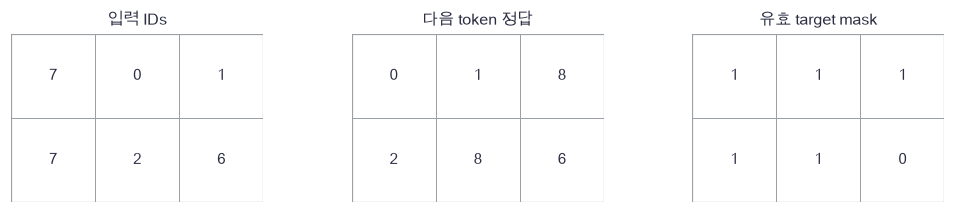

In [19]:
plot_shift(shift_inputs_hand, shift_targets_hand, shift_valid_hand)

🔍 **확인** · 마지막 칸을 제외하면 입력의 다음 열이 현재 정답입니다. 끝에서는 EOS를 맞힙니다. 첫 문서의 끝을 다음 문서 첫 token으로 예측하게 만들면 별개의 확률 문제를 학습합니다. EOS를 끼웠다고 packed attention의 문서 격리가 저절로 생기는 것도 아닙니다.

In [20]:
def shift_documents(documents, pad=256, bos=257, eos=258):
    """문서마다 BOS→본문→EOS를 한 칸 이동하고 오른쪽 padding합니다."""
    width = max(len(ids) + 1 for ids in documents)
    inputs = np.full((len(documents), width), pad, dtype=int)
    targets = np.full_like(inputs, pad)
    valid = np.zeros_like(inputs, dtype=bool)
    for row, ids in enumerate(documents):
        size = len(ids) + 1
        inputs[row, :size] = [bos] + list(ids)
        targets[row, :size] = list(ids) + [eos]
        valid[row, :size] = True
    return inputs, targets, valid

In [21]:
def document_attention_mask(document_ids, valid):
    """한 packed 행에서 같은 문서의 현재/과거 유효 위치만 허용합니다."""
    position = np.arange(len(document_ids))
    same_document = document_ids[:, None] == document_ids[None, :]
    causal = position[:, None] >= position[None, :]
    return same_document & causal & valid[:, None] & valid[None, :]

In [22]:
# 쓰는 것: shift_inputs_hand, shift_targets_hand, shift_valid_hand (앞 절의 정의·실행 셀)
inputs, targets, valid = shift_documents([[0,1],[2]], pad=6, bos=7, eos=8)
np.testing.assert_array_equal(inputs, shift_inputs_hand)  # 검산: 입력 shift = 손계산
np.testing.assert_array_equal(targets, shift_targets_hand)  # 검산: 타깃 shift = 손계산
np.testing.assert_array_equal(valid, shift_valid_hand.astype(bool))  # 검산: 유효 정답5개
empty_inputs, empty_targets, empty_valid = shift_documents([[]])
assert empty_inputs[0,0] == 257, '빈 문서도 BOS로 시작합니다'
assert empty_targets[0,0] == 258, '빈 문서의 첫 정답은 EOS입니다'
packed_mask = document_attention_mask(np.array([0,0,1,1,-1]), np.array([1,1,1,1,0],dtype=bool))
assert not packed_mask[2,0], '두 번째 문서는 첫 문서를 읽지 않습니다'
assert packed_mask[3,2], '같은 문서의 과거는 허용합니다'
assert not packed_mask[2,3], '같은 문서여도 미래는 금지합니다'
assert not packed_mask[4].any(), 'padding query는 전부 막습니다'
print('shift·빈 문서·문서 격리·causal·padding 검산 통과')

shift·빈 문서·문서 격리·causal·padding 검산 통과


### ✏️ 연습 3 · 유효 target의 평균

losses와 valid에서 유효 위치의 평균 value를 채우세요.

In [23]:
def exercise_valid_mean(losses, valid):
    """유효 target의 평균의 계산을 완성합니다."""
    ### 구현할 내용: losses와 valid에서 유효 위치의 평균 value를 채우세요.
    raise NotImplementedError
    return value

In [24]:
def check_valid_mean(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    actual=candidate(np.array([[1.,3.],[2.,100.]]),np.array([[1,1],[1,0]]))
    assert np.isclose(actual,2.), 'PAD의100은 분자와 분모에서 제외합니다'
    print("연습 3 통과")

run_check(check_valid_mean, exercise_valid_mean, hint="유효 target의 평균의 수식과 축을 확인하세요.")

☐ exercise_valid_mean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 유효 target의 평균의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = np.sum(losses * valid) / np.sum(valid)
```

</details>

## 🔑 4. token 번호로 고른 행을 다음 확률로 바꿉니다

**이 절에서 가져갈 것:** embedding은 행 선택이고, 같은 ID가 여러 번 쓰이면 그 행의 기울기를 더합니다.

현재 token이 `apple`이라면 다음에 `is`가 나올 가능성을 배우겠습니다. 아직 이전 문장 전체는 보지 않고 이전 token 하나만 읽습니다. 이 제한된 **bigram 모형**으로 토큰 데이터와 CE의 연결을 먼저 완성합니다.

$$H=E[I]:(N,T,D),\quad S=HW+b:(N,T,V),\quad
\log P=S-\operatorname{logsumexp}(S).$$

$E:(V,D)$는 embedding 표이고 $W:(D,V)$, $b:(V,)$는 다음 token head입니다. 학습 파라미터 수는 $2VD+V$입니다. 이곳은 untied head, 즉 E와 W를 별도로 학습합니다.

유효 위치 수 $M$에서 $dS_{ntv}=m_{nt}(P_{ntv}-\mathbf1[v=y_{nt}])/M$,
$dW=H_{flat}^TdS_{flat}$, $db=\sum_{nt}dS$, $dH=dSW^T$입니다.
$dE_i=\sum_{nt:I_{nt}=i}dH_{nt}$로 같은 행에 온 기여를 누적합니다. 정수 ID 자체를 미분하는 것은 아닙니다.

> **용어** · **embedding**은 ID를 D개 실수로 바꾸는 학습 행 표입니다. **logits**는 softmax 전의 V개 점수입니다. **bigram**은 바로 앞 token 하나만으로 다음 분포를 정하는 모형입니다. **untied**는 입력 표와 출력 표가 독립이라는 뜻입니다.
>
> **코드** · `E[ids]`는 ID에 해당하는 행을 고릅니다. `reshape(-1,D)`는 관측·위치 축을 합칩니다. `np.add.at(dE,ids,dH)`는 반복 ID의 값도 빠짐없이 누적합니다. `_`는 이후 사용하지 않을 반환값입니다.

In [25]:
embedding_ids = np.array([0,1,0])
embedding_table = np.array([[1.,0.],[0.,1.],[.5,.5]])
embedding_head = np.array([[1.,0.,-1.],[0.,1.,-1.]])
embedding_rows = embedding_table[embedding_ids]
embedding_scores = embedding_rows @ embedding_head
embedding_exp = np.exp(embedding_scores - embedding_scores.max(axis=-1, keepdims=True))
embedding_probabilities = embedding_exp / embedding_exp.sum(axis=-1,keepdims=True)

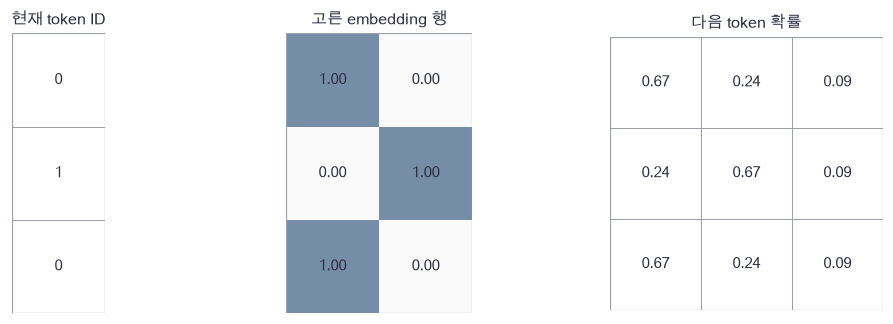

In [26]:
plot_embedding_path(embedding_ids, embedding_rows, embedding_probabilities)

🔍 **확인** · 첫째·셋째 행은 같은 ID라서 같은 embedding과 확률을 가집니다. 그 두 위치의 정답은 달라질 수 있습니다. backward에서 두 위치의 기여를 같은 E의 행에 더해야 합니다. 같은 단어라도 문맥이 다른 현상은 이 모형이 표현하지 못하며 45번 attention으로 확장합니다.

In [27]:
def init_bigram(vocabulary_size, width=8, seed=44):
    """이전 token embedding E와 다음 token 선형 head W,b를 초기화합니다."""
    rng = np.random.default_rng(seed)
    return {'E': rng.normal(0, .15, (vocabulary_size, width)),
            'W': rng.normal(0, .15, (width, vocabulary_size)), 'b': np.zeros(vocabulary_size)}

In [28]:
def bigram_loss(inputs, targets, valid, parameters):
    """유효 target 평균 CE와 E/W/b 전체 미분을 계산합니다. 반복 ID는 누적합니다."""
    # 1) 모든 위치의 logits와 안정 log-softmax를 계산합니다.
    hidden = parameters['E'][inputs]
    logits = hidden @ parameters['W'] + parameters['b']
    shifted = logits - logits.max(axis=-1, keepdims=True)
    logprob = shifted - np.log(np.exp(shifted).sum(axis=-1, keepdims=True))
    count = valid.sum()
    assert count > 0, '유효 target은 적어도 하나여야 합니다'
    flat_targets = targets.ravel()
    rows = np.arange(flat_targets.size)
    flat_logprob = logprob.reshape(-1, logprob.shape[-1])
    loss = -np.sum(flat_logprob[rows, flat_targets] * valid.ravel()) / count
    # 2) p−one_hot의 유효 위치만 나눠서 모든 파라미터로 전달합니다.
    delta = np.exp(logprob).reshape(flat_logprob.shape)
    delta[rows, flat_targets] -= 1
    delta *= valid.ravel()[:, None] / count
    gradients = {'W': hidden.reshape(-1, hidden.shape[-1]).T @ delta, 'b': delta.sum(axis=0)}
    embedding_gradient = delta @ parameters['W'].T
    gradients['E'] = np.zeros_like(parameters['E'])
    np.add.at(gradients['E'], inputs.ravel(), embedding_gradient)
    return float(loss), gradients, logprob

In [29]:
def check_bigram_gradients():
    """반복 입력 ID와 PAD가 있는 작은 모형의 모든 E/W/b 원소를 중심차분합니다."""
    parameters = init_bigram(5,width=3,seed=4401)
    x = np.array([[0,1,0],[2,0,4]])
    y = np.array([[1,0,2],[0,3,4]])
    mask = np.array([[1,1,1],[1,1,0]],dtype=bool)
    loss, gradients, logprob = bigram_loss(x,y,mask,parameters)
    def objective():
        """고정 token·정답·mask의 스칼라 CE입니다."""
        return bigram_loss(x,y,mask,parameters)[0]
    errors=[]
    for name in parameters:
        numeric=numerical_gradient(objective,parameters[name])
        np.testing.assert_allclose(gradients[name],numeric,atol=2e-8,rtol=2e-5)  # 검산: 전체 파라미터 손미분 = 중심차분
        errors.append(np.max(np.abs(gradients[name]-numeric)))
    changed=x.copy()
    changed[1,2]=3
    changed_loss,changed_gradients,_=bigram_loss(changed,y,mask,parameters)
    assert np.isclose(loss,changed_loss), 'PAD 입력을 바꿔도 유효 손실은 같아야 합니다'
    for name in parameters:
        np.testing.assert_allclose(gradients[name],changed_gradients[name])  # 검산: masked 입력값은 전체 미분에 영향 없음
    assert np.all(gradients['E'][4]==0), 'PAD로만 사용한 embedding 행의 미분은0입니다'
    return max(errors)

In [30]:
print('bigram 전체 미분·반복 ID·padding 최대 절대오차:',check_bigram_gradients())
conditional_probabilities = np.array([.5,.25,.8])
sequence_probability = np.prod(conditional_probabilities)
sequence_nll = -np.log(conditional_probabilities).sum()
assert np.isclose(-np.log(sequence_probability),sequence_nll), '조건부 확률 곱의 -log는 CE 합과 같아야 합니다'
print('확률 곱',sequence_probability,'· 문서 NLL',sequence_nll,'· token NLL',sequence_nll/3)

bigram 전체 미분·반복 ID·padding 최대 절대오차: 2.5330842631787753e-10
확률 곱 0.1 · 문서 NLL 2.3025850929940455 · token NLL 0.7675283643313485


### ✏️ 연습 4 · 반복 ID의 기울기를 누적하기

ids에 해당하는 dtable 행에 upstream을 누적하세요.

In [31]:
def exercise_scatter(ids, upstream, rows):
    """반복 ID의 기울기를 누적하기의 계산을 완성합니다."""
    dtable = np.zeros((rows, upstream.shape[1]))
    ### 구현할 내용: ids에 해당하는 dtable 행에 upstream을 누적하세요.
    raise NotImplementedError
    return dtable

In [32]:
def check_scatter(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    actual=candidate(np.array([1,1,0]),np.array([[1.,2.],[3.,4.],[5.,6.]]),3)
    np.testing.assert_allclose(actual,[[5.,6.],[4.,6.],[0.,0.]])  # 검산: 반복 ID1에 두 기여의 합
    print("연습 4 통과")

run_check(check_scatter, exercise_scatter, hint="반복 ID의 기울기를 누적하기의 수식과 축을 확인하세요.")

☐ exercise_scatter: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 반복 ID의 기울기를 누적하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
np.add.at(dtable, ids, upstream)
```

</details>

## 🔑 5. 같은 tokenizer의 held-out 문장과 생성 결과를 읽습니다

**이 절에서 가져갈 것:** 토큰 수·확률 분모·문서 경계를 고정한 평가와 실제 EOS 생성은 따로 확인합니다.

같은 과일 문장을 byte 20개로 나누거나 합쳐진 token 8개로 나누면 예측 횟수가 다릅니다. 총 NLL이 가령12로 같아도 PPL은 $e^{12/20}$과 $e^{12/8}$로 다릅니다.

$$PPL=\exp\left(\frac{\text{전체 유효 token NLL 합}}{\text{전체 유효 token 수}}\right),\qquad
B_{path}=\frac{\text{NLL 합}}{\log2\cdot\text{원문 UTF-8 byte 수}}.$$

PPL은 같은 tokenizer·EOS 규약에서 비교합니다. byte당 비용은 서로 다른 token 분모를 원문 단위로 옮겨 보는 보조값입니다. 여기의 NLL은 **정해진 canonical token 경로**의 비용입니다. 같은 문자열로 복원되는 다른 token 열의 확률을 모두 합하지 않으므로, 일반적인 문자열 주변 확률이라고 주장하지 않습니다. EOS의 비용은 포함하고 BOS/PAD는 제외하며, byte 분모에는 제어 토큰을 더하지 않습니다.

> **용어** · **perplexity(PPL)**는 token 평균 NLL의 지수입니다. **held-out**은 학습에 쓰지 않은 문장입니다. **canonical 경로**는 고정 tokenizer가 정하는 한 token 열입니다. **탐욕 생성(greedy)**은 매 단계 가장 큰 점수의 token을 고릅니다.

아래 숫자는 분모를 설명하는 손계산입니다. 실제 학습은 그 뒤에서 시작합니다.

In [33]:
# 쓰는 것: encode_bpe, toy_rules, utf8_ids (앞 절의 정의·실행 셀)
budget_text='red apple is sweet.'
budget_counts=[len(budget_text),len(utf8_ids(budget_text)),len(encode_bpe(budget_text,toy_rules))]
assumed_counts=np.array([20.,8.])
budget_costs=np.stack([assumed_counts,12/assumed_counts,np.exp(12/assumed_counts)])

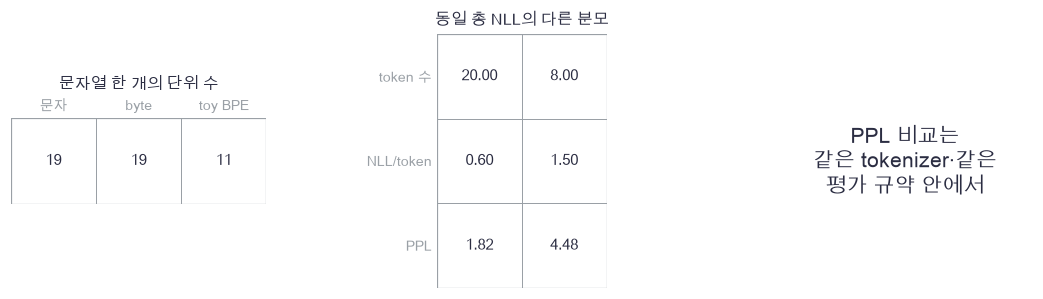

In [34]:
plot_token_budget(budget_counts,['문자','byte','toy BPE'],budget_costs)

🔍 **확인** · 가운데 표의 PPL 차이는 모델 우열이 아니라 분모 차이입니다. 실제 실험은 고유 문장48개를 seed4402로 섞어 train36개/test12개로 나눕니다. BPE는 train36개에서만 32회까지 병합합니다. 같은 tokenizer로 두 분할을 평가하며 test는 설정·중단 시점 선택에 쓰지 않습니다.

작은 bigram을 seed44, 폭8, full batch SGD 학습률0.8로200회 갱신합니다. 이 표본은 사람이 만든 좁은 문법이므로 자연어 전반의 품질을 평가하지 않습니다. 다음 단원에서도 작고 분리된 실험이라는 범위를 유지합니다.

> **코드** · 여러 `for`가 있는 목록 생성은 색×과일×맛의 조합을 만듭니다. `rng.permutation(N)`은 중복 없는 순서를 섞습니다. `.ravel()`은 배열을 일렬로 펼칩니다. `*batch`는 `(inputs,targets,valid)`의 세 인자를 풀어 전달합니다. `dict.values()`는 사전의 배열 값들입니다.

In [35]:
# 쓰는 것: decode_bpe, encode_bpe, shift_documents, train_byte_bpe (앞 절의 정의·실행 셀)
all_texts=[f'{color} {fruit} is {taste}.' for color in ['red','green','gold','blue']
           for fruit in ['apple','pear','plum','grape'] for taste in ['sweet','sour','fresh']]
permutation=np.random.default_rng(4402).permutation(len(all_texts))
train_texts=[all_texts[i] for i in permutation[:36]]
test_texts=[all_texts[i] for i in permutation[36:]]
assert not set(train_texts)&set(test_texts), '고유 문장 분할은 겹치면 안 됩니다'
vocabulary,rules=train_byte_bpe(train_texts,merges=32)
frozen_rules=tuple(rules)
train_documents=[encode_bpe(text,rules) for text in train_texts]
test_documents=[encode_bpe(text,rules) for text in test_texts]
train_batch=shift_documents(train_documents)
test_batch=shift_documents(test_documents)
vocabulary_size=max(max(vocabulary),258)+1
for text in test_texts:
    assert decode_bpe(encode_bpe(text,rules),vocabulary)==text, 'test 문자열도 정확히 복원해야 합니다'
assert tuple(rules)==frozen_rules, '평가 tokenization은 규칙을 갱신하지 않습니다'
print('train/test 문장 수:',len(train_texts),len(test_texts),'· V:',vocabulary_size,'· 병합:',len(rules))

train/test 문장 수: 36 12 · V: 291 · 병합: 32


In [36]:
def train_bigram(train_batch, test_batch, vocabulary_size, steps=200):
    """고정 full batch SGD로 학습하고 같은 tokenizer의 NLL을 기록합니다."""
    # 쓰는 것: bigram_loss, init_bigram (앞 절의 정의·실행 셀)
    parameters = init_bigram(vocabulary_size)
    history = []
    for step in range(steps + 1):
        loss, gradients, _ = bigram_loss(*train_batch, parameters)
        if step % 50 == 0:
            evaluation = bigram_loss(*test_batch, parameters)[0]
            history.append([step, loss, evaluation])
        if step == steps:
            break
        for name in parameters:
            parameters[name] -= .8 * gradients[name]
    return parameters, np.asarray(history)

In [37]:
def greedy_bigram(parameters, max_tokens=40, bos=257, eos=258, pad=256):
    """BOS에서 시작해 마지막 token만으로 탐욕 생성합니다. EOS 또는 상한에서 멈춥니다."""
    generated = []
    current = bos
    for _ in range(max_tokens):
        logits = parameters['E'][current] @ parameters['W'] + parameters['b']
        logits[[pad, bos]] = -np.inf
        current = int(np.argmax(logits))
        generated.append(current)
        if current == eos:
            break
    return generated, bool(generated and generated[-1] == eos)

In [38]:
parameters,training_history=train_bigram(train_batch,test_batch,vocabulary_size)
print('학습 파라미터 수:',sum(value.size for value in parameters.values()))
assert np.isfinite(training_history).all(), '모든 train/test NLL은 유한해야 합니다'

학습 파라미터 수: 4947


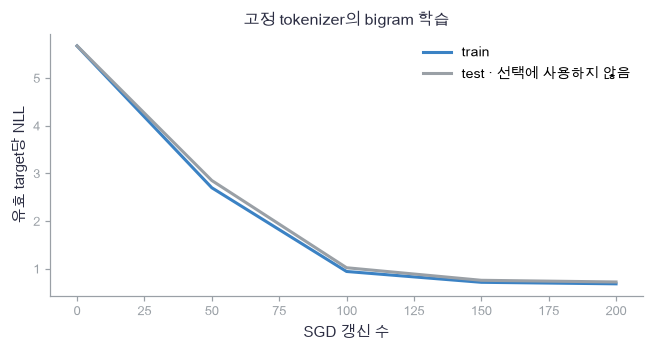

In [39]:
plot_learning(training_history)

In [40]:
# 쓰는 것: bigram_loss, decode_bpe, frozen_rules, rules, test_batch, test_texts, train_batch, train_texts, vocabulary (앞 절의 정의·실행 셀)
for name,texts,batch in [('train',train_texts,train_batch),('test',test_texts,test_batch)]:
    nll,_,_=bigram_loss(*batch,parameters)
    token_count=int(batch[2].sum())
    byte_count=sum(len(text.encode('utf-8')) for text in texts)
    print(name,'유효 target',token_count,'NLL/token',round(nll,4),'PPL',round(np.exp(nll),3),
          'canonical bits/raw-byte',round(nll*token_count/(np.log(2)*byte_count),3))
generated_ids,terminated=greedy_bigram(parameters)
content_ids=generated_ids[:-1] if terminated else generated_ids
print('greedy IDs:',generated_ids,'· EOS 종료:',terminated)
try:
    generated_text=decode_bpe(content_ids,vocabulary)
    print('생성 문자열:',repr(generated_text))
except UnicodeDecodeError:
    print('생성 byte 열은 유효한 UTF-8이 아닙니다:',b''.join(vocabulary[i] for i in content_ids))
assert tuple(rules)==frozen_rules, '언어모델 학습과 생성도 tokenizer 규칙을 바꾸지 않습니다'

train 유효 target 245 NLL/token 0.6833 PPL 1.98 canonical bits/raw-byte 0.347
test 유효 target 91 NLL/token 0.7223 PPL 2.059 canonical bits/raw-byte 0.421
greedy IDs: [279, 264, 282, 276, 258] · EOS 종료: True
생성 문자열: 'green pear is fresh.'


🔍 **확인** · 학습 곡선과 독립 test NLL은 같은 tokenizer에서 읽습니다. 생성은 BOS에서 시작해 이전 token만 보고 진행하므로 반복하거나 짧게 끝날 수 있습니다. 탐욕 생성 때 PAD/BOS는 금지하고 EOS 또는40토큰 상한에서 멈춥니다. 이 출력 제한은 학습 softmax의 확률을 그대로 샘플링한 절차는 아닙니다.

byte로 모든 입력을 **표현**할 수 있어도 임의로 생성한 byte 열이 유효한 UTF-8이라는 보장은 없습니다. 위 코드는 부적합한 출력에 대체 문자를 몰래 넣지 않고 실제 byte를 보고합니다. 구조는 embedding+선형 bigram, 목적은 next-token CE, 갱신은 SGD, 사용은 정답 없는 생성입니다. BPE 빈도 학습은 이 네트워크의 미분 경로 밖입니다.

### ✏️ 연습 5 · 같은 tokenizer의 perplexity

전체 NLL total_nll과 유효 token_count로 perplexity를 구하세요.

In [41]:
def exercise_ppl(total_nll, token_count):
    """같은 tokenizer의 perplexity의 계산을 완성합니다."""
    ### 구현할 내용: 전체 NLL total_nll과 유효 token_count로 perplexity를 구하세요.
    raise NotImplementedError
    return perplexity

In [42]:
def check_ppl(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert np.isclose(candidate(4*np.log(2),4),2.), '매 token의 확률이1/2이면 PPL2입니다'
    assert np.isclose(candidate(4*np.log(2),2),4.), '분모가2이면 같은 총 NLL의 PPL4입니다'
    print("연습 5 통과")

run_check(check_ppl, exercise_ppl, hint="같은 tokenizer의 perplexity의 수식과 축을 확인하세요.")

☐ exercise_ppl: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 같은 tokenizer의 perplexity의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
perplexity = np.exp(total_nll / token_count)
```

</details>

## ✏️ 끝 연습 · A–D

본문의 상태를 바꾸지 않고 다른 작은 입력으로 확인합니다.

### ✏️ 연습 A · 문서 마지막 EOS까지 세기

문서별 본문 길이 lengths에서 유효 target 총수 total을 채우세요.

In [43]:
def exercise_count(lengths):
    """문서 마지막 EOS까지 세기의 계산을 완성합니다."""
    ### 구현할 내용: 문서별 본문 길이 lengths에서 유효 target 총수 total을 채우세요.
    raise NotImplementedError
    return total

In [44]:
def check_count(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(np.array([2,0,3]))==8, '각 문서의 EOS까지3+1+4=8입니다'
    print("연습 A 통과")

run_check(check_count, exercise_count, hint="문서 마지막 EOS까지 세기의 수식과 축을 확인하세요.")

☐ exercise_count: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 문서 마지막 EOS까지 세기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = np.sum(lengths + 1)
```

</details>

### ✏️ 연습 B · 겹친 쌍 빈도 확인하기

ids의 인접한 두 값이 모두 value인 위치 수 count를 채우세요.

In [45]:
def exercise_overlap(ids, value):
    """겹친 쌍 빈도 확인하기의 계산을 완성합니다."""
    ### 구현할 내용: ids의 인접한 두 값이 모두 value인 위치 수 count를 채우세요.
    raise NotImplementedError
    return count

In [46]:
def check_overlap(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(np.array([1,1,1,1]),1)==3, '겹친 인접 쌍은3개입니다'
    assert candidate(np.array([1]),1)==0, '한 값에는 쌍이 없습니다'
    print("연습 B 통과")

run_check(check_overlap, exercise_overlap, hint="겹친 쌍 빈도 확인하기의 수식과 축을 확인하세요.")

☐ exercise_overlap: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 겹친 쌍 빈도 확인하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
count = np.sum((ids[:-1] == value) & (ids[1:] == value))
```

</details>

### ✏️ 연습 C · 문서 확률의 로그로 바꾸기

조건부 probabilities의 음의 로그 합 nll을 채우세요.

In [47]:
def exercise_chain(probabilities):
    """문서 확률의 로그로 바꾸기의 계산을 완성합니다."""
    ### 구현할 내용: 조건부 probabilities의 음의 로그 합 nll을 채우세요.
    raise NotImplementedError
    return nll

In [48]:
def check_chain(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert np.isclose(candidate(np.array([.5,.25])),np.log(8)), '확률곱1/8의 NLL은log8입니다'
    print("연습 C 통과")

run_check(check_chain, exercise_chain, hint="문서 확률의 로그로 바꾸기의 수식과 축을 확인하세요.")

☐ exercise_chain: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 문서 확률의 로그로 바꾸기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
nll = -np.log(probabilities).sum()
```

</details>

### ✏️ 연습 D · 같은 문서 조건을 배열로 만들기

document_ids의 두 위치가 같은 문서인지 same 행렬을 채우세요.

In [49]:
def exercise_same_doc(document_ids):
    """같은 문서 조건을 배열로 만들기의 계산을 완성합니다."""
    ### 구현할 내용: document_ids의 두 위치가 같은 문서인지 same 행렬을 채우세요.
    raise NotImplementedError
    return same

In [50]:
def check_same_doc(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([0,0,1])),[[1,1,0],[1,1,0],[0,0,1]])  # 검산: 두 문서의 block 구조
    print("연습 D 통과")

run_check(check_same_doc, exercise_same_doc, hint="같은 문서 조건을 배열로 만들기의 수식과 축을 확인하세요.")

☐ exercise_same_doc: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 같은 문서 조건을 배열로 만들기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
same = document_ids[:,None] == document_ids[None,:]
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

- **설명:** byte가 모든 입력을 표현한다는 것과 생성 byte가 유효한 글이라는 것은 어떻게 다른가요? train에서 배운 BPE와 test tokenization을 구분할 수 있나요?
- **수식:** 문서 확률의 곱에서 token CE 합과 유효 token 평균을 유도하고 EOS가 분모에 들어가는 이유를 설명할 수 있나요?
- **구현:** 반복 ID의 embedding 미분을 `np.add.at`으로 누적하고 모든 E/W/b 원소를 중심차분할 수 있나요?
- **변형 검산:** 빈 문서·연속 공백·미학습 한글·겹친 쌍·다른 길이 padding을 바꾸어도 왕복과 경계가 유지되는지 확인할 수 있나요?

45 작은 GPT는 같은 토큰 배열에 causal attention·정규화·FFN을 붙여 문맥을 늘립니다. 46 생성에서는 확률을 실제로 샘플링하는 규칙과 계산 재사용을 분리합니다.